> Note: This notebook has been superseded by `notebooks/concepts_age_unified.ipynb` (single place for both AoA-lexicon and story-age concept distributions).


# AoA lexicon embedding concepts

This notebook analyzes **Age of Acquisition (AoA) ratings** as a lexical resource, without using your story dataset.

- **AoA age source:** human AoA ratings per word/lemma from the Kuperman et al. lexicon (e.g. `AoA_Kup_lem`).
- **Not used here:** Amazon/YouTube story reading age (`age_mid`).

Goal: embed AoA words with a generic pretrained embedding (e.g. GloVe via `gensim`), then inspect continuous AoA gradients and clusters to get human-interpretable semantic themes associated with earlier vs later acquired vocabulary.


In [70]:
import os
os.chdir('/Users/tzl/repos/story-features')
print('cwd:', os.getcwd())


cwd: /Users/tzl/repos/story-features


In [71]:
from __future__ import annotations

import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')


## Load AoA lexicon

Preferred file: `data/aoa/AoA_51715_words.xlsx`.

We use a lemma-based AoA column when available (commonly `AoA_Kup_lem`).


In [72]:
def load_aoa_lexicon() -> tuple[Path, pd.DataFrame]:
    candidates = [
        Path('data/aoa/AoA_51715_words.xlsx'),
        Path('data/aoa/AoA_51715_words.csv'),
        Path('data/aoa/AoA_ratings_Kuperman_et_al_BRM_with_PoS.xlsx'),
    ]
    p = next((x for x in candidates if x.exists()), None)
    if p is None:
        raise FileNotFoundError('No AoA lexicon found under data/aoa/')
    if p.suffix in {'.xlsx', '.xls'}:
        df = pd.read_excel(p)
    else:
        df = pd.read_csv(p, low_memory=False)
    return p, df


aoa_path, aoa_df = load_aoa_lexicon()
print('AoA loaded:', aoa_path, aoa_df.shape)
aoa_df.columns


AoA loaded: data/aoa/AoA_51715_words.xlsx (51715, 16)


Index(['Word', 'Alternative.spelling', 'Freq_pm', 'Dom_PoS_SUBTLEX',
       'Nletters', 'Nphon', 'Nsyll', 'Lemma_highest_PoS', 'AoA_Kup',
       'Perc_known', 'AoA_Kup_lem', 'Perc_known_lem', 'AoA_Bird_lem',
       'AoA_Bristol_lem', 'AoA_Cort_lem', 'AoA_Schock'],
      dtype='object')

In [73]:
def guess_cols(df: pd.DataFrame) -> tuple[str, str]:
    cols = list(df.columns)
    col_norm = {c: str(c).strip().lower() for c in cols}

    # Prefer lemma tokens if the file provides them.
    lemma_cols = [c for c in cols if col_norm[c] in {'lemma', 'lem'} or 'lemma' in col_norm[c]]
    word_cols = [c for c in cols if col_norm[c] in {'word', 'wordform', 'word_form'}]
    if lemma_cols:
        word_col = lemma_cols[0]
    elif word_cols:
        word_col = word_cols[0]
    else:
        word_col = cols[0]

    # AoA column preference (lemma-based AoA if present).
    age_pref = ['aoa_kup_lem', 'aoa_kup', 'rating.mean', 'rating_mean', 'aoa']
    age_col = None
    for want in age_pref:
        for c in cols:
            if col_norm[c] == want:
                age_col = c
                break
        if age_col:
            break
    if age_col is None:
        # last resort: first numeric-ish col
        for c in cols:
            if pd.to_numeric(df[c], errors='coerce').notna().any():
                age_col = c
                break
    if age_col is None:
        raise ValueError('Could not infer AoA age column')

    return word_col, age_col


word_col, age_col = guess_cols(aoa_df)
print('Using word_col:', word_col)
print('Using age_col: ', age_col)

d = aoa_df[[word_col, age_col]].copy()
d = d.rename(columns={word_col: 'word', age_col: 'aoa'})
d['word'] = d['word'].astype(str).str.lower().str.strip()
d['aoa'] = pd.to_numeric(d['aoa'], errors='coerce')
d = d[d['word'].str.match(r'^[a-z]+$') & d['aoa'].notna()].drop_duplicates('word')
print('usable entries:', d.shape)
d.head()


Using word_col: Lemma_highest_PoS
Using age_col:  AoA_Kup_lem
usable entries: (31104, 2)


,word,aoa
0,a,2.893384
1,aardvark,9.890000
2,abacus,8.690000
4,abalone,12.230000
6,abandon,8.320000


### AoA distribution (all usable lexicon entries)

This shows the distribution of AoA ratings **before** filtering to the embedding vocabulary.


AoA summary:


count    31104.000000
mean        11.000148
std          3.044161
min          1.580000
25%          8.940000
50%         11.170000
75%         13.200000
max         25.000000
Name: aoa, dtype: float64

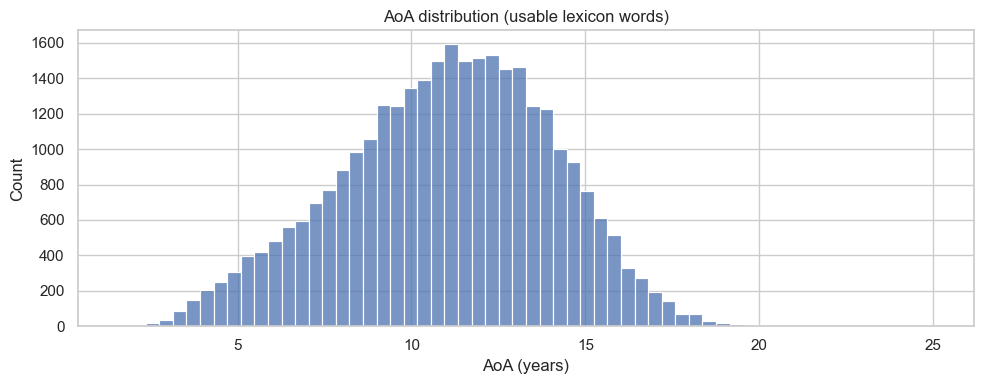

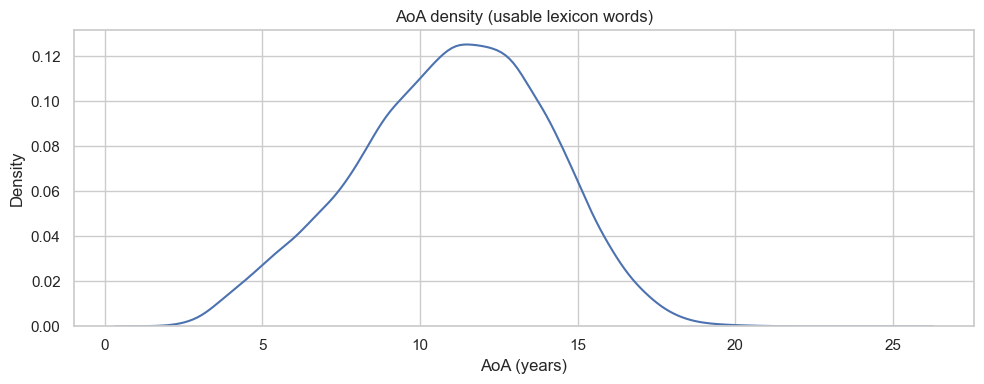

In [74]:
plt.figure(figsize=(10,4))
sns.histplot(d["aoa"], bins=60)
plt.title("AoA distribution (usable lexicon words)")
plt.xlabel("AoA (years)")
plt.tight_layout()

plt.figure(figsize=(10,4))
sns.kdeplot(d["aoa"], bw_adjust=1.1)
plt.title("AoA density (usable lexicon words)")
plt.xlabel("AoA (years)")
plt.tight_layout()

print("AoA summary:")
display(d["aoa"].describe())


## Load pretrained embeddings (Gensim)

This downloads a small pretrained embedding the first time (internet required). If you prefer fully offline, point this to a local `.vec`/`.txt` embedding file and load it instead.


In [75]:
EMBEDDING_NAME = 'glove-wiki-gigaword-100'  # small + fast

import gensim.downloader as api
wv = api.load(EMBEDDING_NAME)
print('loaded embedding:', EMBEDDING_NAME, 'dim=', wv.vector_size)


loaded embedding: glove-wiki-gigaword-100 dim= 100


In [76]:
in_vocab = d['word'].apply(lambda w: w in wv)
d2 = d[in_vocab].copy()
print('AoA words in embedding vocab:', d2.shape[0], '/', d.shape[0])

X = np.vstack([wv[w] for w in d2['word'].tolist()]).astype(np.float32)
y = d2['aoa'].to_numpy(dtype=np.float32)

X.shape, (float(y.min()), float(y.max()))


AoA words in embedding vocab: 29163 / 31104


((29163, 100), (1.5800000429153442, 25.0))

## Continuous AoA map (UMAP/PCA)


/opt/anaconda3/envs/story-features/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


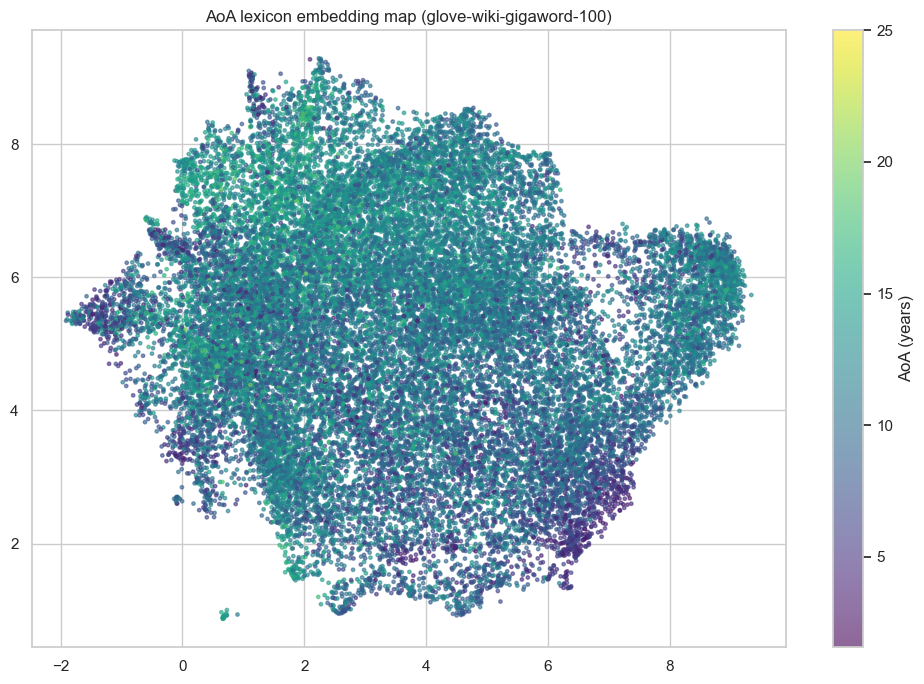

In [77]:
def embed_2d(X: np.ndarray) -> np.ndarray:
    try:
        import umap
        return umap.UMAP(n_neighbors=25, min_dist=0.25, random_state=0).fit_transform(X)
    except Exception:
        from sklearn.decomposition import PCA
        return PCA(n_components=2, random_state=0).fit_transform(X)


xy = embed_2d(X)
plt.figure(figsize=(10,7))
sc = plt.scatter(xy[:,0], xy[:,1], c=y, cmap='viridis', s=6, alpha=0.6)
plt.colorbar(sc, label='AoA (years)')
plt.title(f'AoA lexicon embedding map ({EMBEDDING_NAME})')
plt.tight_layout()


## Continuous density + dispersion metrics in concept space

UMAP/PCA give a 2D concept space (`xy`). We can quantify how AoA varies across the space using: 
- **Normalized 2D densities** for early vs late AoA quantiles and their **Jensen–Shannon divergence**.
- **Within-group dispersion** (trace of covariance in 2D).
- How well 2D coordinates predict AoA (R² of ridge / KNN).

Note: UMAP is not metric-preserving; treat these as descriptive, not absolute.


AoA quantiles: 8.260000228881836 13.569999694824219 | early n= 5848 late n= 5849
JS divergence (early vs late densities): 0.17034060595627948
dispersion trace early: 9.29448774479484 late: 6.913038777488885
CV R2 ridge(x,y)->AoA: 0.10720193401240763
CV R2 knn(x,y)->AoA:  0.19039027276370268


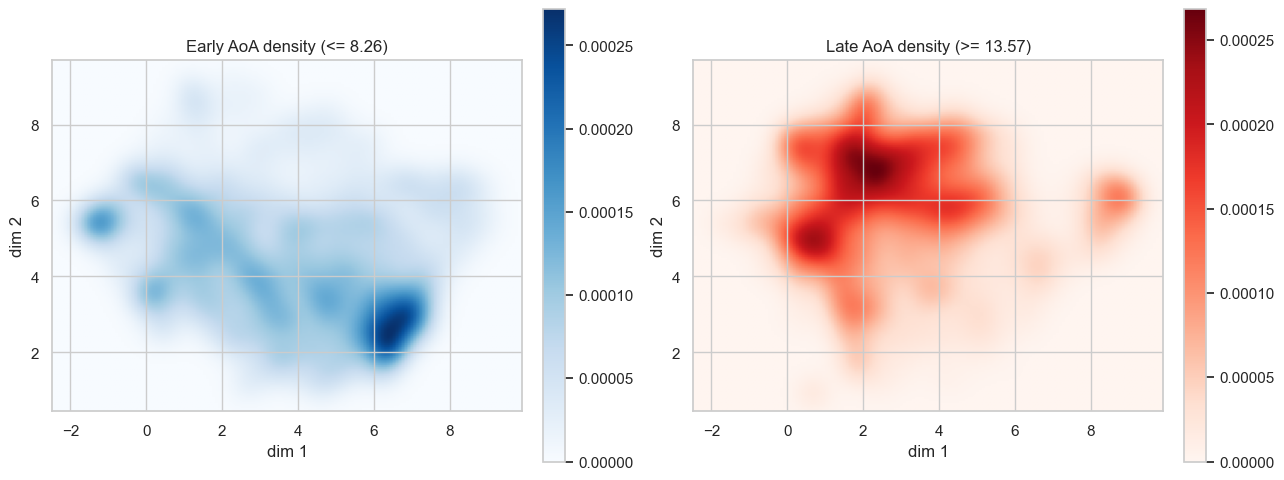

In [78]:
from sklearn.neighbors import KernelDensity, KNeighborsRegressor
from sklearn.metrics import r2_score

emb = pd.DataFrame({
    "x": xy[:,0],
    "y": xy[:,1],
    "aoa": y,
})

# define early/late quantiles
q_lo, q_hi = emb["aoa"].quantile([0.2, 0.8]).tolist()
early = emb[emb["aoa"] <= q_lo].copy()
late  = emb[emb["aoa"] >= q_hi].copy()
print("AoA quantiles:", q_lo, q_hi, "| early n=", len(early), "late n=", len(late))

# grid for density evaluation
xmin, xmax = emb["x"].min(), emb["x"].max()
ymin, ymax = emb["y"].min(), emb["y"].max()
padx = 0.05 * (xmax - xmin + 1e-9)
pady = 0.05 * (ymax - ymin + 1e-9)
xmin -= padx; xmax += padx
ymin -= pady; ymax += pady
gx = np.linspace(xmin, xmax, 160)
gy = np.linspace(ymin, ymax, 160)
xx, yy = np.meshgrid(gx, gy)
grid = np.c_[xx.ravel(), yy.ravel()]

def kde2d(df, bw=0.35):
    X2 = df[["x","y"]].to_numpy()
    kde = KernelDensity(kernel="gaussian", bandwidth=bw)
    kde.fit(X2)
    logp = kde.score_samples(grid)
    p = np.exp(logp)
    p = p / (p.sum() + 1e-12)
    return p.reshape(xx.shape)

p_early = kde2d(early)
p_late  = kde2d(late)

# Jensen–Shannon divergence between normalized densities
P = p_early.ravel(); Q = p_late.ravel()
M = 0.5*(P+Q)
def _kl(a,b):
    m = (a>0) & (b>0)
    return float(np.sum(a[m] * (np.log(a[m]) - np.log(b[m]))))
js = 0.5*_kl(P,M) + 0.5*_kl(Q,M)
print("JS divergence (early vs late densities):", js)

# dispersion in 2D (trace of covariance)
def disp(df):
    Z = df[["x","y"]].to_numpy()
    C = np.cov(Z.T)
    return float(np.trace(C))
print("dispersion trace early:", disp(early), "late:", disp(late))

# how well 2D predicts AoA (ridge vs KNN)
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
X2 = emb[["x","y"]].to_numpy()
yy_ = emb["aoa"].to_numpy()
kf = KFold(n_splits=5, shuffle=True, random_state=0)
pred_r = np.zeros_like(yy_, dtype=float)
pred_k = np.zeros_like(yy_, dtype=float)
for tr, te in kf.split(X2):
    rr = Ridge(alpha=1.0)
    rr.fit(X2[tr], yy_[tr])
    pred_r[te] = rr.predict(X2[te])
    knn = KNeighborsRegressor(n_neighbors=25, weights="distance")
    knn.fit(X2[tr], yy_[tr])
    pred_k[te] = knn.predict(X2[te])
print("CV R2 ridge(x,y)->AoA:", float(r2_score(yy_, pred_r)))
print("CV R2 knn(x,y)->AoA: ", float(r2_score(yy_, pred_k)))

# plot density comparison
fig, axes = plt.subplots(1, 2, figsize=(13,5))
im0 = axes[0].imshow(p_early, origin="lower", extent=[xmin,xmax,ymin,ymax], cmap="Blues")
axes[0].set_title(f"Early AoA density (<= {q_lo:.2f})")
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)
im1 = axes[1].imshow(p_late, origin="lower", extent=[xmin,xmax,ymin,ymax], cmap="Reds")
axes[1].set_title(f"Late AoA density (>= {q_hi:.2f})")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)
for ax in axes:
    ax.set_xlabel("dim 1")
    ax.set_ylabel("dim 2")
plt.tight_layout()


## AoA gradient surface over concept space (kNN + KDE support mask)

We fit a **kNN regression** `AoA ≈ f(x,y)` using the 2D coordinates (`xy`) and visualize the predicted AoA as a smooth heatmap.
A KDE-based support mask helps avoid interpreting regions with almost no words.


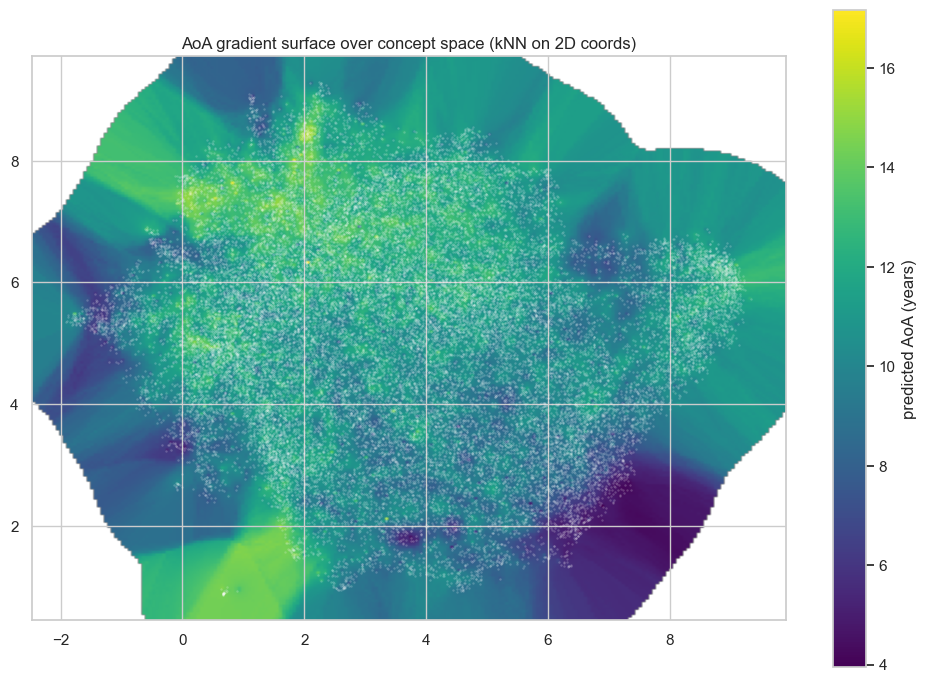

In [79]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import MinMaxScaler

# train regressor on observed 2D points
X2 = emb[["x","y"]].to_numpy()
yy_ = emb["aoa"].to_numpy()

knn = KNeighborsRegressor(n_neighbors=35, weights="distance")
knn.fit(X2, yy_)

# grid
gx = np.linspace(xmin, xmax, 220)
gy = np.linspace(ymin, ymax, 220)
xx, yy = np.meshgrid(gx, gy)
grid2 = np.c_[xx.ravel(), yy.ravel()]
pred_grid = knn.predict(grid2).reshape(xx.shape)

# support mask via KDE over all points
# support mask via KDE over all points (use the same grid as the heatmap)
kde_all = KernelDensity(kernel='gaussian', bandwidth=0.4)
kde_all.fit(X2)
logp_all = kde_all.score_samples(grid2)
p_all = np.exp(logp_all).reshape(xx.shape)
p_all = p_all / (p_all.sum() + 1e-12)
thr = np.quantile(p_all, 0.15)  # mask lowest-density 15% of grid
mask = p_all < thr

pred_masked = pred_grid.copy()
pred_masked[mask] = np.nan

plt.figure(figsize=(10,7))
im = plt.imshow(pred_masked, origin="lower", extent=[xmin,xmax,ymin,ymax], cmap="viridis")
plt.colorbar(im, label="predicted AoA (years)")
plt.scatter(emb["x"], emb["y"], s=3, c="white", alpha=0.20, linewidths=0)
plt.title("AoA gradient surface over concept space (kNN on 2D coords)")
plt.tight_layout()


## Data-driven 3-group AoA cutpoints via sliding-window semantic change (PCA eigenvalues)

We find two AoA cutpoints (→ 3 bands) by looking for AoA regions where the embedding distribution changes fastest.

Steps:
1) PCA on the full embedding space `Xz` and keep the number of PCs needed to explain a target variance (e.g., 90%).
2) Sort words by AoA.
3) Slide a window over the sorted list; compute the centroid in PC space per window.
4) Compute the centroid “speed” between adjacent windows; pick the two strongest peaks as cutpoints.


PCs to reach 90% variance: 75 cum= 0.9012187123298645
Suggested cutpoints (AoA years): [4.959227561950684, 5.464738368988037]


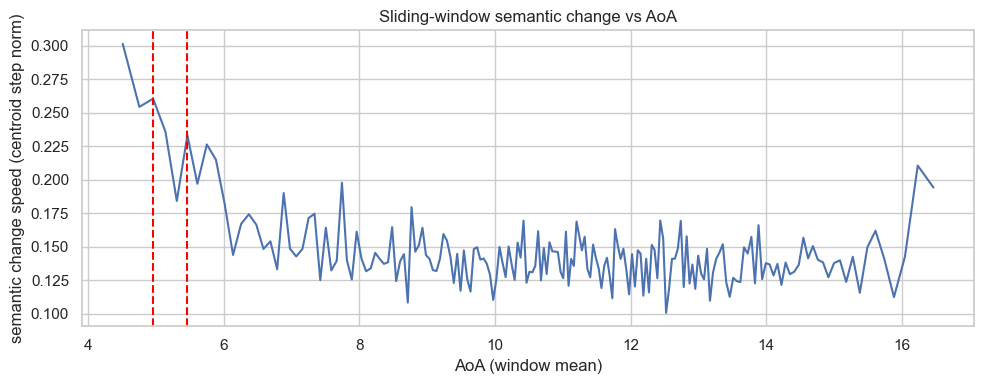

In [80]:
from sklearn.decomposition import PCA
from scipy.signal import find_peaks

# PCA in embedding space (not the 2D map)
# Ensure Xz exists even if you ran cells out of order
try:
    Xz
except NameError:
    from sklearn.preprocessing import StandardScaler
    scaler = StandardScaler(with_mean=True, with_std=True)
    Xz = scaler.fit_transform(X)

pca_full = PCA(n_components=min(200, Xz.shape[1]), random_state=0)
Z = pca_full.fit_transform(Xz)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)
d_keep = int(np.searchsorted(cum, 0.90) + 1)
print("PCs to reach 90% variance:", d_keep, "cum=", float(cum[d_keep-1]))

# sort by AoA
ord_idx = np.argsort(y)
y_sorted = y[ord_idx]
Zs = Z[ord_idx, :d_keep]

WIN = 1200   # adjust depending on lexicon size; larger = smoother
STEP = 150
centroids = []
cent_aoa = []
for start in range(0, len(y_sorted) - WIN + 1, STEP):
    sl = slice(start, start + WIN)
    centroids.append(Zs[sl].mean(axis=0))
    cent_aoa.append(float(np.mean(y_sorted[sl])))
centroids = np.vstack(centroids)
cent_aoa = np.array(cent_aoa)

# centroid speed
speed = np.linalg.norm(np.diff(centroids, axis=0), axis=1)
speed_aoa = 0.5 * (cent_aoa[1:] + cent_aoa[:-1])

plt.figure(figsize=(10,4))
plt.plot(speed_aoa, speed)
plt.xlabel("AoA (window mean)")
plt.ylabel("semantic change speed (centroid step norm)")
plt.title("Sliding-window semantic change vs AoA")
plt.tight_layout()

# pick 2 strongest peaks with minimum separation
peaks, props = find_peaks(speed, distance=max(1, int(0.6/ (STEP/max(y_sorted)-min(y_sorted)+1e-9))))
if len(peaks) == 0:
    print("No peaks found; try smaller WIN/STEP")
else:
    top = peaks[np.argsort(speed[peaks])][::-1][:2]
    cutpoints = sorted([float(speed_aoa[i]) for i in top])
    print("Suggested cutpoints (AoA years):", cutpoints)
    for cp in cutpoints:
        plt.axvline(cp, color="red", linestyle="--")
    plt.show()


## Optimal cutoffs via separability search (2-bin and 3-bin)

Instead of fixed quantiles, we **search cutpoints** on the age variable that maximize separability in embedding space.

- 2-bin: choose threshold `t` maximizing centroid distance.
- 3-bin: choose `(t1,t2)` maximizing between-class scatter (centroid separation).

Includes an optional permutation test that re-runs the same search to correct for cherry-picking cutpoints.


In [ ]:
import numpy as np
from itertools import combinations

# Uses: Xz (standardized embedding matrix) and y (AoA years) from earlier cells.

def _centroid_sep(X, y_mask_a):
    A = X[y_mask_a]
    B = X[~y_mask_a]
    if len(A)==0 or len(B)==0:
        return -1.0
    return float(np.linalg.norm(A.mean(axis=0) - B.mean(axis=0)))

def best_2bin_cutoff(X, y, min_frac=0.15, n_grid=120):
    y = np.asarray(y)
    lo, hi = np.quantile(y, [min_frac, 1-min_frac])
    ts = np.linspace(lo, hi, n_grid)
    best = (-1.0, None)
    for t in ts:
        m = y <= t
        if m.mean() < min_frac or (1-m.mean()) < min_frac:
            continue
        s = _centroid_sep(X, m)
        if s > best[0]:
            best = (s, float(t))
    return best

def between_scatter_objective(X, y, t1, t2):
    # 3 groups: <=t1, (t1,t2], >t2
    g1 = X[y <= t1]
    g2 = X[(y > t1) & (y <= t2)]
    g3 = X[y > t2]
    groups = [g1,g2,g3]
    if any(len(g)==0 for g in groups):
        return -1.0
    mus = [g.mean(axis=0) for g in groups]
    ns = [len(g) for g in groups]
    mu = (ns[0]*mus[0] + ns[1]*mus[1] + ns[2]*mus[2]) / float(sum(ns))
    # trace of between-class scatter: sum n_k * ||mu_k - mu||^2
    return float(sum(n * np.dot(m-mu, m-mu) for n,m in zip(ns,mus)))

def best_3bin_cutoffs(X, y, min_frac=0.15, grid_n=40):
    y = np.asarray(y)
    qs = np.linspace(min_frac, 1-min_frac, grid_n)
    cands = np.quantile(y, qs)
    best = (-1.0, None, None)
    for i in range(len(cands)):
        for j in range(i+1, len(cands)):
            t1 = float(cands[i]); t2=float(cands[j])
            # min group fraction constraint
            f1 = np.mean(y <= t1)
            f2 = np.mean((y > t1) & (y <= t2))
            f3 = np.mean(y > t2)
            if min(f1,f2,f3) < min_frac:
                continue
            s = between_scatter_objective(X, y, t1, t2)
            if s > best[0]:
                best = (s, t1, t2)
    return best

S2, t = best_2bin_cutoff(Xz, y, min_frac=0.15, n_grid=140)
S3, t1, t2 = best_3bin_cutoffs(Xz, y, min_frac=0.15, grid_n=55)
print("Best 2-bin cutoff:", t, "stat=", S2)
print("Best 3-bin cutoffs:", (t1, t2), "stat=", S3)

DO_PERM = False
B = 200
if DO_PERM:
    rng = np.random.default_rng(0)
    perm2=[]
    perm3=[]
    for _ in range(B):
        yp = rng.permutation(y)
        s2,_t = best_2bin_cutoff(Xz, yp, min_frac=0.15, n_grid=140)
        s3,_a,_b = best_3bin_cutoffs(Xz, yp, min_frac=0.15, grid_n=55)
        perm2.append(s2)
        perm3.append(s3)
    p2 = float(np.mean(np.array(perm2) >= S2))
    p3 = float(np.mean(np.array(perm3) >= S3))
    print("perm p-value 2-bin:", p2)
    print("perm p-value 3-bin:", p3)


## Learn an “AoA direction” + interpret by neighbors

Fit ridge regression `AoA ~ embedding(word)`; use the learned direction to rank words (earlier vs later acquired). Then probe semantic neighborhoods around extreme words.


In [81]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler(with_mean=True, with_std=True)
Xz = scaler.fit_transform(X)

# quick CV sanity
kf = KFold(n_splits=5, shuffle=True, random_state=0)
pred = np.zeros_like(y, dtype=np.float64)
for tr, te in kf.split(Xz):
    rr = Ridge(alpha=10.0, random_state=0)
    rr.fit(Xz[tr], y[tr])
    pred[te] = rr.predict(Xz[te])

corr = float(np.corrcoef(pred, y)[0,1])
mae = float(np.mean(np.abs(pred - y)))
print('CV corr(pred, AoA)=', corr, 'MAE=', mae)

# fit on all to get a stable direction
rr = Ridge(alpha=10.0, random_state=0)
rr.fit(Xz, y)
w = rr.coef_.astype(np.float64)
w = w / (np.linalg.norm(w) + 1e-12)

scores = (Xz @ w).astype(np.float64)
d2 = d2.copy()
d2['aoa_axis_score'] = scores
d2.sort_values('aoa_axis_score').head(10)


CV corr(pred, AoA)= 0.7210768097167478 MAE= 1.662127962419167


,word,aoa,aoa_axis_score
29723,my,2.715564,-8.414962
51597,you,4.346085,-8.344554
22665,i,2.790163,-8.117742
51606,your,4.100974,-8.115212
27909,me,3.280385,-7.728324
25322,kids,3.861149,-6.653791
2903,baby,3.840000,-6.557586
50445,we,5.038790,-6.509367
19475,get,3.170000,-6.500581
46213,thing,4.580000,-6.322205


In [82]:
print('Most EARLY by axis (lowest score):')
display(d2.sort_values('aoa_axis_score', ascending=True).head(25))

print('Most LATE by axis (highest score):')
display(d2.sort_values('aoa_axis_score', ascending=False).head(25))


Most EARLY by axis (lowest score):


,word,aoa,aoa_axis_score
29723,my,2.715564,-8.414962
51597,you,4.346085,-8.344554
22665,i,2.790163,-8.117742
51606,your,4.100974,-8.115212
27909,me,3.280385,-7.728324
25322,kids,3.861149,-6.653791
2903,baby,3.840000,-6.557586
50445,we,5.038790,-6.509367
19475,get,3.170000,-6.500581
46213,thing,4.580000,-6.322205


Most LATE by axis (highest score):


,word,aoa,aoa_axis_score
19773,glutathione,16.00,4.038519
22587,hyperplasia,17.09,3.953863
42878,spectrometry,16.15,3.945442
44821,superoxide,14.67,3.911784
7987,citrate,15.80,3.848400
22945,immunosuppressive,13.77,3.756235
1739,antifungal,12.00,3.755446
37023,recombinant,16.06,3.736875
351,acetic,13.75,3.598971
1346,amicus,15.40,3.594569


In [83]:
def nn_words(word: str, topn: int = 12):
    if word not in wv:
        return []
    return [(w, float(s), float(d2.loc[d2['word']==w, 'aoa'].iloc[0]) if (d2['word']==w).any() else np.nan)
            for w, s in wv.most_similar(word, topn=topn)]

# pick a few extremes and inspect their neighbors
early_words = d2.sort_values('aoa_axis_score', ascending=True)['word'].head(3).tolist()
late_words = d2.sort_values('aoa_axis_score', ascending=False)['word'].head(3).tolist()
print('early words:', early_words)
print('late words: ', late_words)

for w in early_words + late_words:
    print('\n== neighbors for', w, 'AoA=', float(d2.loc[d2['word']==w, 'aoa'].iloc[0]), '==')
    for nn, sim, nn_aoa in nn_words(w, topn=12):
        print(f'  {nn:>12s}  sim={sim:.3f}  aoa={nn_aoa}')


early words: ['my', 'you', 'i']
late words:  ['glutathione', 'hyperplasia', 'spectrometry']

== neighbors for my AoA= 2.715564 ==
          your  sim=0.908  aoa=4.100974000000001
            me  sim=0.855  aoa=3.280385
           our  sim=0.823  aoa=4.346085
             i  sim=0.822  aoa=2.7901629999999997
           you  sim=0.815  aoa=4.346085
           her  sim=0.794  aoa=5.092075
          mind  sim=0.790  aoa=5.37
            'd  sim=0.770  aoa=nan
          know  sim=0.766  aoa=4.5
            'm  sim=0.764  aoa=nan
    everything  sim=0.764  aoa=4.441998
          good  sim=0.760  aoa=3.55

== neighbors for you AoA= 4.346085 ==
           'll  sim=0.932  aoa=nan
           n't  sim=0.915  aoa=nan
          know  sim=0.910  aoa=4.5
             i  sim=0.902  aoa=2.7901629999999997
            do  sim=0.900  aoa=3.6
           're  sim=0.897  aoa=nan
          sure  sim=0.896  aoa=4.85
             ?  sim=0.894  aoa=nan
            'd  sim=0.893  aoa=nan
           get  sim=0.88

## Cluster concepts (optional)

Cluster the embedding space and inspect clusters by mean AoA + representative words.


In [87]:
from sklearn.cluster import KMeans

K = 20
km = KMeans(n_clusters=K, random_state=0, n_init='auto')
lab = km.fit_predict(Xz)
d2c = d2.copy()
d2c['cluster'] = lab

summ = (
    d2c.groupby('cluster')
      .agg(n=('word','size'), mean_aoa=('aoa','mean'))
      .sort_values('mean_aoa')
      .reset_index()
)

def top_words_for_cluster(c, n=12):
    g = d2c[d2c['cluster']==c].sort_values('aoa')
    # show a mix: early-ish and late-ish in the cluster
    w1 = g['word'].head(n//2).tolist()
    w2 = g['word'].tail(n - n//2).tolist()
    return ', '.join(w1 + w2)

summ['example_words'] = summ['cluster'].apply(lambda c: top_words_for_cluster(c, n=14))
summ.head(30)


,cluster,n,mean_aoa,example_words
0,1,1213,6.403170,"mom, yes, dad, count, mother, no, my, franchis..."
1,5,736,8.686934,"spoon, carrot, snack, eat, soap, chicken, oran..."
2,7,1615,9.386269,"shoe, sock, nose, toe, bathroom, neck, clothes..."
3,19,692,9.673201,"fire, arms, truck, boat, spill, bus, airplane,..."
4,11,1102,9.681904,"need, key, help, steps, turkey, welcome, step,..."
5,17,1054,9.833324,"wet, bed, bath, backyard, foot, hill, circle, ..."
6,12,840,10.013763,"water, food, drop, fell, bubble, farm, plant, ..."
7,0,1147,10.139679,"animal, flower, puppy, spider, duck, bird, kit..."
8,8,1195,10.331107,"nap, hug, bye, clap, goodbye, splash, nighttim..."
9,14,2426,10.629589,"momma, mama, potty, ouch, mommy, daddy, grandm..."


## Post-hoc LLM labels (optional)

This is a GemmaScope-style *interpretability* step: use an open-source LLM to assign short human-readable labels to each cluster based on its representative words.

- Default is **OFF** (writes prompts only).
- Turn `RUN_LLM=True` to generate labels locally (may require a GPU / lots of RAM depending on model).


In [85]:
from pathlib import Path
import json
import re
import pandas as pd

out_dir = Path('artifacts/aoa_lexicon_concepts')
out_dir.mkdir(parents=True, exist_ok=True)
df = summ[['cluster','mean_aoa','example_words']]
df = df.dropna(subset=['example_words']).copy()
df['example_words'] = df['example_words'].astype(str)

RUN_LLM = False
MODEL_NAME = os.environ.get('CONCEPT_LABEL_MODEL', '').strip()
# Example: export CONCEPT_LABEL_MODEL='gpt-oss' (or a local HF model path you have cached)

def make_prompt(row: pd.Series) -> str:
    words = row['example_words']
    header = {k: row[k] for k in row.index if k != 'example_words'}
    return (
        'You are labeling a semantic cluster of words.\n'
        'Task: Provide a short concept label and 1-sentence description.\n'
        'Return STRICT JSON with keys: label, description, keywords (list of strings).\n'
        f'Cluster metadata: {header}\n'
        f'Representative words: {words}\n'
    )

prompts = []
for _, row in df.iterrows():
    prompts.append({
        'cluster': int(row['cluster']),
        'prompt': make_prompt(row),
    })
prompts_path = out_dir / 'label_prompts.jsonl'
with prompts_path.open('w', encoding='utf-8') as f:
    for p in prompts:
        f.write(json.dumps(p, ensure_ascii=False) + "\n")
print('Wrote prompts:', prompts_path, 'n=', len(prompts))

if not RUN_LLM:
    print('RUN_LLM=False: skipping generation. Set RUN_LLM=True and CONCEPT_LABEL_MODEL to run.')
else:
    if not MODEL_NAME:
        raise ValueError('Set CONCEPT_LABEL_MODEL to an open-source LLM name/path (and ensure transformers/torch are installed).')
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer

    tok = AutoTokenizer.from_pretrained(MODEL_NAME)
    mdl = AutoModelForCausalLM.from_pretrained(MODEL_NAME, device_map="auto")
    mdl.eval()

    def generate(prompt: str) -> str:
        inputs = tok(prompt, return_tensors="pt")
        # move to model device (device_map=auto)
        dev = next(mdl.parameters()).device
        inputs = {k: v.to(dev) for k, v in inputs.items()}
        with torch.no_grad():
            out = mdl.generate(**inputs, max_new_tokens=180, do_sample=False)
        txt = tok.decode(out[0], skip_special_tokens=True)
        return txt[len(prompt):].strip()

rows=[]
for p in prompts:
    raw = generate(p['prompt'])
    # extract first JSON object in the output
    m = re.search(r"\{.*\}", raw, flags=re.S)
    if not m:
        rows.append({'cluster': p['cluster'], 'raw': raw, 'label': '', 'description': '', 'keywords': ''})
        continue
    try:
        obj = json.loads(m.group(0))
    except Exception:
        rows.append({'cluster': p['cluster'], 'raw': raw, 'label': '', 'description': '', 'keywords': ''})
        continue
    rows.append({
        'cluster': p['cluster'],
        'label': str(obj.get('label','')).strip(),
        'description': str(obj.get('description','')).strip(),
        'keywords': json.dumps(obj.get('keywords', []), ensure_ascii=False),
        'raw': raw,
    })

labels = pd.DataFrame(rows)
labels_path = out_dir / 'cluster_labels.csv'
labels.to_csv(labels_path, index=False)
print('Wrote labels:', labels_path)
labels.head()


Wrote prompts: artifacts/aoa_lexicon_concepts/label_prompts.jsonl n= 20
RUN_LLM=False: skipping generation. Set RUN_LLM=True and CONCEPT_LABEL_MODEL to run.


NameError: name 'generate' is not defined

## Quantitative tests (no Moran's I)

These summarize how strongly the 2D concept space relates to the age variable, without relying on visual inspection.

- CV **R²** for predicting age from 2D coords (ridge + kNN).
- **Local smoothness**: average variance of age among k nearest neighbors in 2D.
- **Kruskal–Wallis** test of age differences across clusters + effect size.


In [ ]:
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor, NearestNeighbors
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# Requires: xy (2D coords) and y (AoA values) from earlier cells
df2 = pd.DataFrame({"x": xy[:,0], "y": xy[:,1], "age": y}).copy()
X2 = df2[["x","y"]].to_numpy(dtype=np.float32)
yy = df2["age"].to_numpy(dtype=np.float32)

# CV R2
kf = KFold(n_splits=5, shuffle=True, random_state=0)
pred_r = np.zeros_like(yy, dtype=float)
pred_k = np.zeros_like(yy, dtype=float)
for tr, te in kf.split(X2):
    rr = Ridge(alpha=1.0)
    rr.fit(X2[tr], yy[tr])
    pred_r[te] = rr.predict(X2[te])
    knn = KNeighborsRegressor(n_neighbors=35, weights="distance")
    knn.fit(X2[tr], yy[tr])
    pred_k[te] = knn.predict(X2[te])
print("CV R2 ridge(x,y)->age:", float(r2_score(yy, pred_r)))
print("CV R2 knn(x,y)->age: ", float(r2_score(yy, pred_k)))

# local smoothness: neighbor variance
KNN_K = 25
nbrs = NearestNeighbors(n_neighbors=KNN_K+1).fit(X2)
idx = nbrs.kneighbors(X2, return_distance=False)[:,1:]
neigh_var = np.var(yy[idx], axis=1)
print("mean neighbor age variance (k=25):", float(np.mean(neigh_var)))

from scipy.stats import kruskal

# word-level clustering table is d2c (from the clustering cell)
if "d2c" in globals():
    groups = [g["aoa"].to_numpy(dtype=float) for _, g in d2c.groupby("cluster")]
    stat, p = kruskal(*groups)
    n = len(d2c)
    k = d2c["cluster"].nunique()
    eps2 = (stat - k + 1) / (n - k)
    print("Kruskal-Wallis H=", float(stat), "p=", float(p), "epsilon^2=", float(eps2))
else:
    print("No d2c found; run the clustering cell first.")
